# NARPS gain effect in the equal-indifference group

**Question.** Does the gain-parametric effect estimate show a positive group mean in vmPFC?

This notebook runs the reproducible group analysis in `analysis.py`, which validates all supplied inputs, performs one-sample whole-brain inference with positive-direction sign-flip max-T familywise correction, and writes tables and figures. It does not repeat preprocessing or participant-level modeling.


## Model and inference plan

- Treat the 54 supplied unthresholded participant contrast estimates as observations in a one-sample group model.
- Keep all participants after checksum, geometry, and finite-value checks.
- Use the intersection of nonzero map coverage (same 54 participants at every tested voxel).
- Test the directional positive effect using 5,000 sign-flip permutations and the maximum t statistic across the whole analysis mask (FWER α=.05).
- Summarize a 12-mm sphere centered at MNI (0, 42, −10) as a secondary anatomical vmPFC description; it does not replace whole-brain correction.


In [1]:
from pathlib import Path
import json, os, subprocess
import pandas as pd

root = Path.cwd()
prepared_python = "/Users/johnlee/.local/state/stamped-in-practice/narps-neutral-v1/common-environment/.pixi/envs/default/bin/python"
run_env = os.environ.copy()
run_env["MPLBACKEND"] = "Agg"
subprocess.run([prepared_python, str(root / "analysis.py")], cwd=root, env=run_env, check=True)
summary = json.loads((root / "results/summary.json").read_text())
pd.Series(summary, name="value")


{
  "n": 54,
  "n_excluded": 0,
  "n_mask_voxels": 198029,
  "mask_coverage_threshold": 1.0,
  "n_permutations": 5000,
  "seed": 20261016,
  "primary_direction": "positive, one-sided",
  "maxT_FWER_alpha": 0.05,
  "maxT_threshold_95": 5.396595001220703,
  "global_max_t": 6.617173235381884,
  "global_max_t_coordinate_mni_mm": [
    -26.0,
    -102.0,
    -3.599997043609619
  ],
  "global_max_p_fwer": 0.0009998000399920016,
  "n_fwer_significant": 24,
  "vmPFC_max_t": 1.7003842798828679,
  "vmPFC_min_p_fwer": 1.0,
  "vmPFC_sphere_center_mni_mm": [
    0.0,
    42.0,
    -10.0
  ],
  "vmPFC_sphere_radius_mm": 12,
  "vmPFC_voxels": 742,
  "vmPFC_mean_cope": -0.00782527551948824,
  "vmPFC_sd_subject_means": 0.09957142557500918,
  "vmPFC_median_subject_mean": -0.007196318920626589,
  "vmPFC_ci95_t": [
    -0.03500304300944232,
    0.019352491970465836
  ],
  "vmPFC_t": -0.5775130367597023,
  "vmPFC_wilcoxon_p_one_sided": 0.758577082731166,
  "vmPFC_leave_one_out_mean_range": [
    -0.0123405

n                                                                                 54
n_excluded                                                                         0
n_mask_voxels                                                                 198029
mask_coverage_threshold                                                          1.0
n_permutations                                                                  5000
seed                                                                        20261016
primary_direction                                                positive, one-sided
maxT_FWER_alpha                                                                 0.05
maxT_threshold_95                                                           5.396595
global_max_t                                                                6.617173
global_max_t_coordinate_mni_mm                   [-26.0, -102.0, -3.599997043609619]
global_max_p_fwer                                                

## Results

The summary below reports the vmPFC estimate and the whole-brain corrected inference. Corrected effects elsewhere do not count as support for the vmPFC hypothesis. The participant-level model regressor was variance-normalized upstream, so these cope values are not effects per currency unit.


In [2]:
summary


{'n': 54,
 'n_excluded': 0,
 'n_mask_voxels': 198029,
 'mask_coverage_threshold': 1.0,
 'n_permutations': 5000,
 'seed': 20261016,
 'primary_direction': 'positive, one-sided',
 'maxT_FWER_alpha': 0.05,
 'maxT_threshold_95': 5.396595001220703,
 'global_max_t': 6.617173235381884,
 'global_max_t_coordinate_mni_mm': [-26.0, -102.0, -3.599997043609619],
 'global_max_p_fwer': 0.0009998000399920016,
 'n_fwer_significant': 24,
 'vmPFC_max_t': 1.7003842798828679,
 'vmPFC_min_p_fwer': 1.0,
 'vmPFC_sphere_center_mni_mm': [0.0, 42.0, -10.0],
 'vmPFC_sphere_radius_mm': 12,
 'vmPFC_voxels': 742,
 'vmPFC_mean_cope': -0.00782527551948824,
 'vmPFC_sd_subject_means': 0.09957142557500918,
 'vmPFC_median_subject_mean': -0.007196318920626589,
 'vmPFC_ci95_t': [-0.03500304300944232, 0.019352491970465836],
 'vmPFC_t': -0.5775130367597023,
 'vmPFC_wilcoxon_p_one_sided': 0.758577082731166,
 'vmPFC_leave_one_out_mean_range': [-0.012340579647284232,
  -0.00301927127617062],
 'vmPFC_leave_one_out_t_range': [-0.94

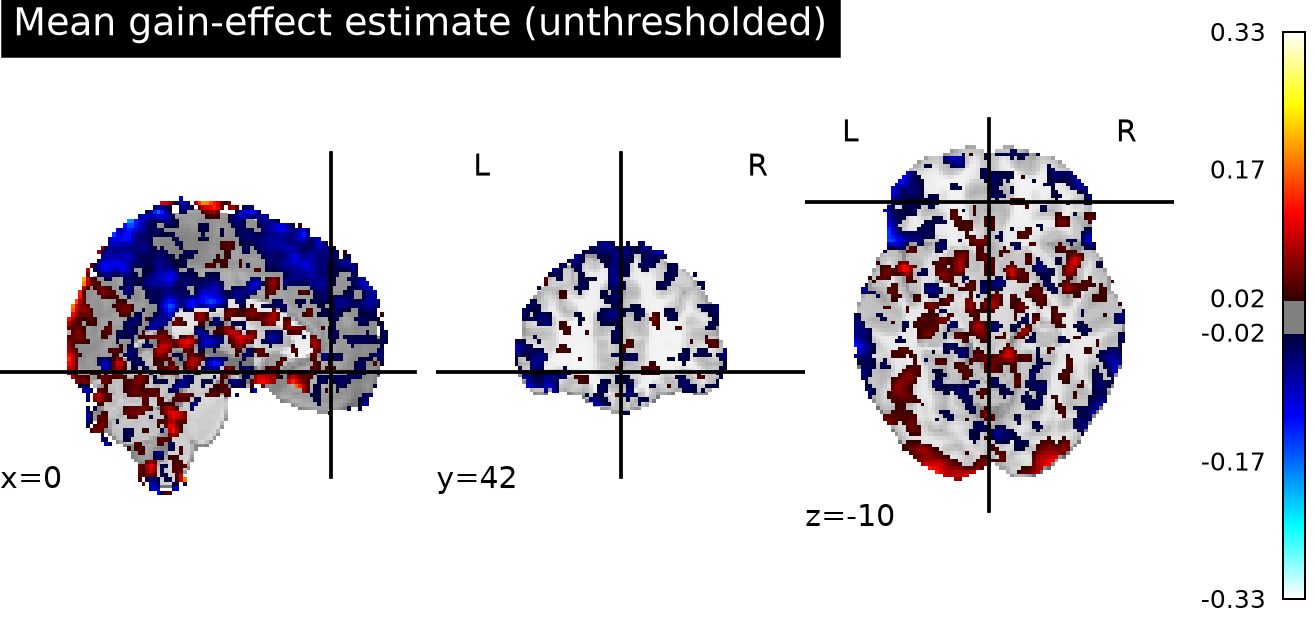

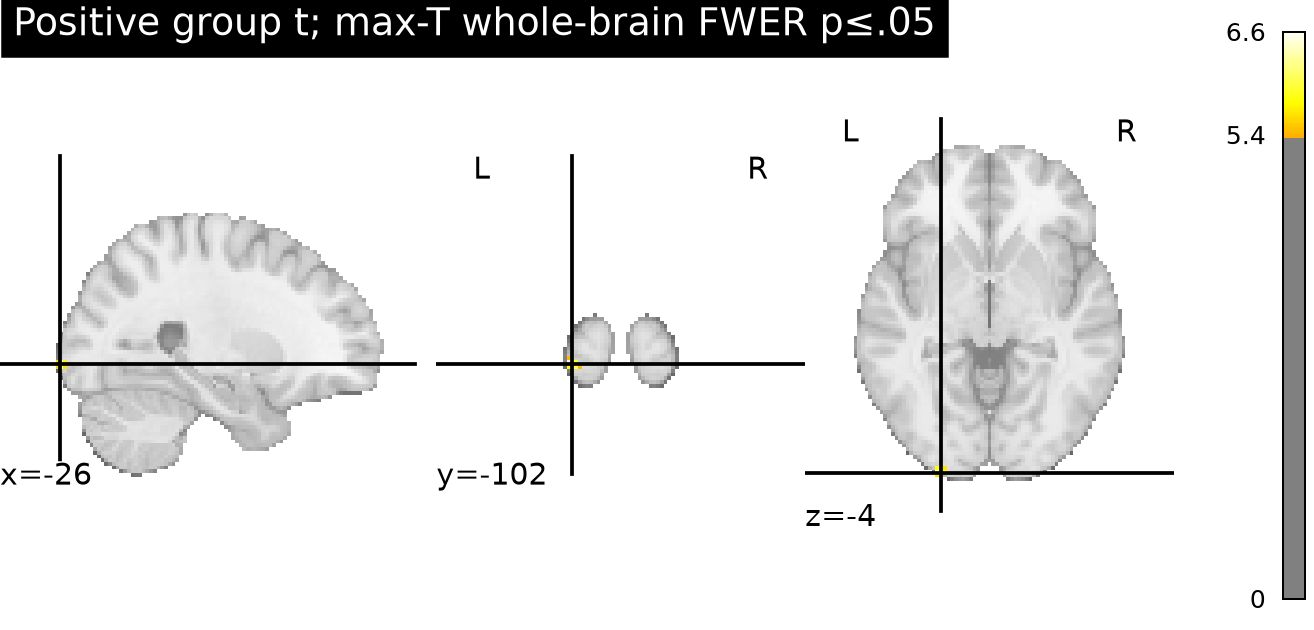

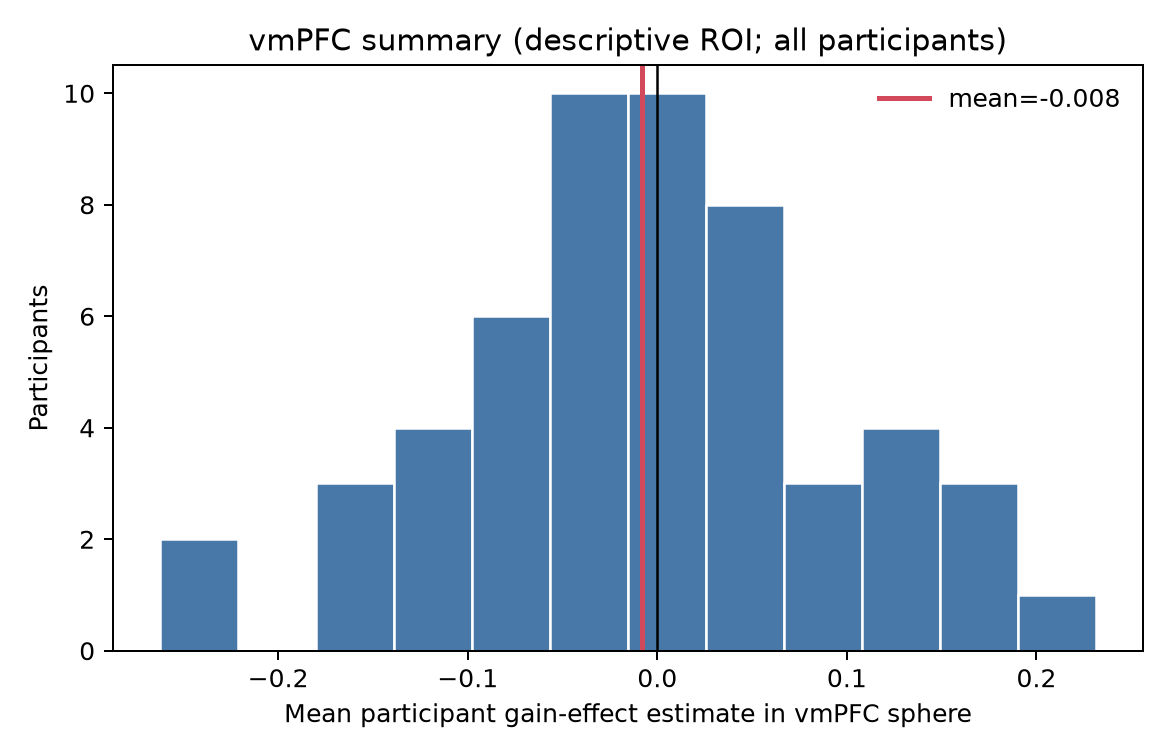

In [3]:
from IPython.display import display, Image
for filename in ["mean_gain_effect.png", "whole_brain_maxT.png", "vmPFC_subject_distribution.png"]:
    display(Image(filename=str(root / "figures" / filename)))


## Interpretation and limits

A nonsignificant vmPFC result means these supplied maps do not provide evidence for a positive average group effect under this model and correction. It does not establish a zero effect or rule out smaller effects. The input maps are participant contrast estimates, not test statistics; without first-level variance maps, this analysis cannot precision-weight participants or reconstruct the full first-level uncertainty. The upstream gain regressor was centered and variance-normalized, response duration followed response time, and gain was modeled separately from loss. The estimate therefore reflects that specific model, not a causal effect per dollar or a gain-versus-loss comparison.
